In [1]:
from pathlib import Path
from utils2 import *
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from task1.utils import plot_images

cells_dir = Path.cwd().resolve().parent / "Data" / "cells"
masks_dir = Path.cwd().resolve().parent / "Data" / "masks_pts"

pairs = []

for img_path in sorted(cells_dir.iterdir()):
    mask_name = img_path.name.replace('cell', 'mask_pts')
    mask_path = masks_dir / mask_name
    
    if mask_path.exists():
        pairs.append((str(img_path), str(mask_path)))

print(f"Found pairs of image-mask: {len(pairs)}, first pair: {pairs[0]}")

Found pairs of image-mask: 352, first pair: ('C:\\Users\\galem\\Desktop\\FIT-CTU\\ANI-PIV\\Data\\cells\\cell_0_0.png', 'C:\\Users\\galem\\Desktop\\FIT-CTU\\ANI-PIV\\Data\\masks_pts\\mask_pts_0_0.png')


In [2]:
split_idx = int(len(pairs) * 0.8)
batch_size = 8
train_dataset = CiliaDataset(pairs[:split_idx], img_size=256, augment=True)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = CiliaDataset(pairs[split_idx:], img_size=256, augment=False)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [3]:
model = UNet().to(device)
loss_fn = nn.BCEWithLogitsLoss()
#loss_fn = DiceLoss()                       
#loss_fn = BCEDiceLoss(alpha=0.5)           
#loss_fn = FocalLoss(alpha=0.25, gamma=2.0)  
#loss_fn = TverskyLoss(alpha=0.7, beta=0.3)
#loss_fn = FocalLoss(alpha=0.7, gamma=1.0) 

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
num_epochs = 10

# Use one fixed training sample to compare its image, target mask, and prediction.
preview_img, preview_mask = train_dataset[0]
epoch_outs = []
history = []

In [4]:
for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    for imgs, masks in train_dataloader:
        imgs = imgs.to(device)
        masks = masks.to(device)
        # Zero out the gradients
        optimizer.zero_grad()
        # Forward pass, returns logits
        outputs = model(imgs)
        loss = loss_fn(outputs, masks)
        # Backward pass
        loss.backward()
        # Update weights
        optimizer.step()
        # convert tensor to scalar
        train_loss += loss.item()

    evaluate_model(model, val_dataloader, device=device, epoch=epoch, loss_fn=loss_fn, history=history, epoch_outs=epoch_outs, preview_img=preview_img, train_loss=train_loss / len(train_dataloader))


Epoch [1] | Train Loss: 0.3480 | Val Loss: 0.4522 | Dice: 0.4505 | Acc: 0.8432 | Prec: 0.2875 | Rec: 0.9849 | F1: 0.4436 | 
Epoch [2] | Train Loss: 0.2269 | Val Loss: 0.1928 | Dice: 0.8006 | Acc: 0.9705 | Prec: 0.7024 | Rec: 0.9361 | F1: 0.8004 | 
Epoch [3] | Train Loss: 0.1662 | Val Loss: 0.1456 | Dice: 0.8103 | Acc: 0.9729 | Prec: 0.7158 | Rec: 0.9443 | F1: 0.8135 | 
Epoch [4] | Train Loss: 0.1279 | Val Loss: 0.1279 | Dice: 0.7751 | Acc: 0.9655 | Prec: 0.6519 | Rec: 0.9673 | F1: 0.7781 | 
Epoch [5] | Train Loss: 0.1073 | Val Loss: 0.1336 | Dice: 0.7360 | Acc: 0.9573 | Prec: 0.6008 | Rec: 0.9672 | F1: 0.7391 | 
Epoch [6] | Train Loss: 0.0923 | Val Loss: 0.1166 | Dice: 0.5112 | Acc: 0.9598 | Prec: 0.9421 | Rec: 0.3804 | F1: 0.5383 | 
Epoch [7] | Train Loss: 0.0829 | Val Loss: 0.0802 | Dice: 0.8106 | Acc: 0.9747 | Prec: 0.7509 | Rec: 0.8931 | F1: 0.8149 | 
Epoch [8] | Train Loss: 0.0777 | Val Loss: 0.0836 | Dice: 0.7081 | Acc: 0.9719 | Prec: 0.9278 | Rec: 0.5960 | F1: 0.7234 | 
Epoch [9

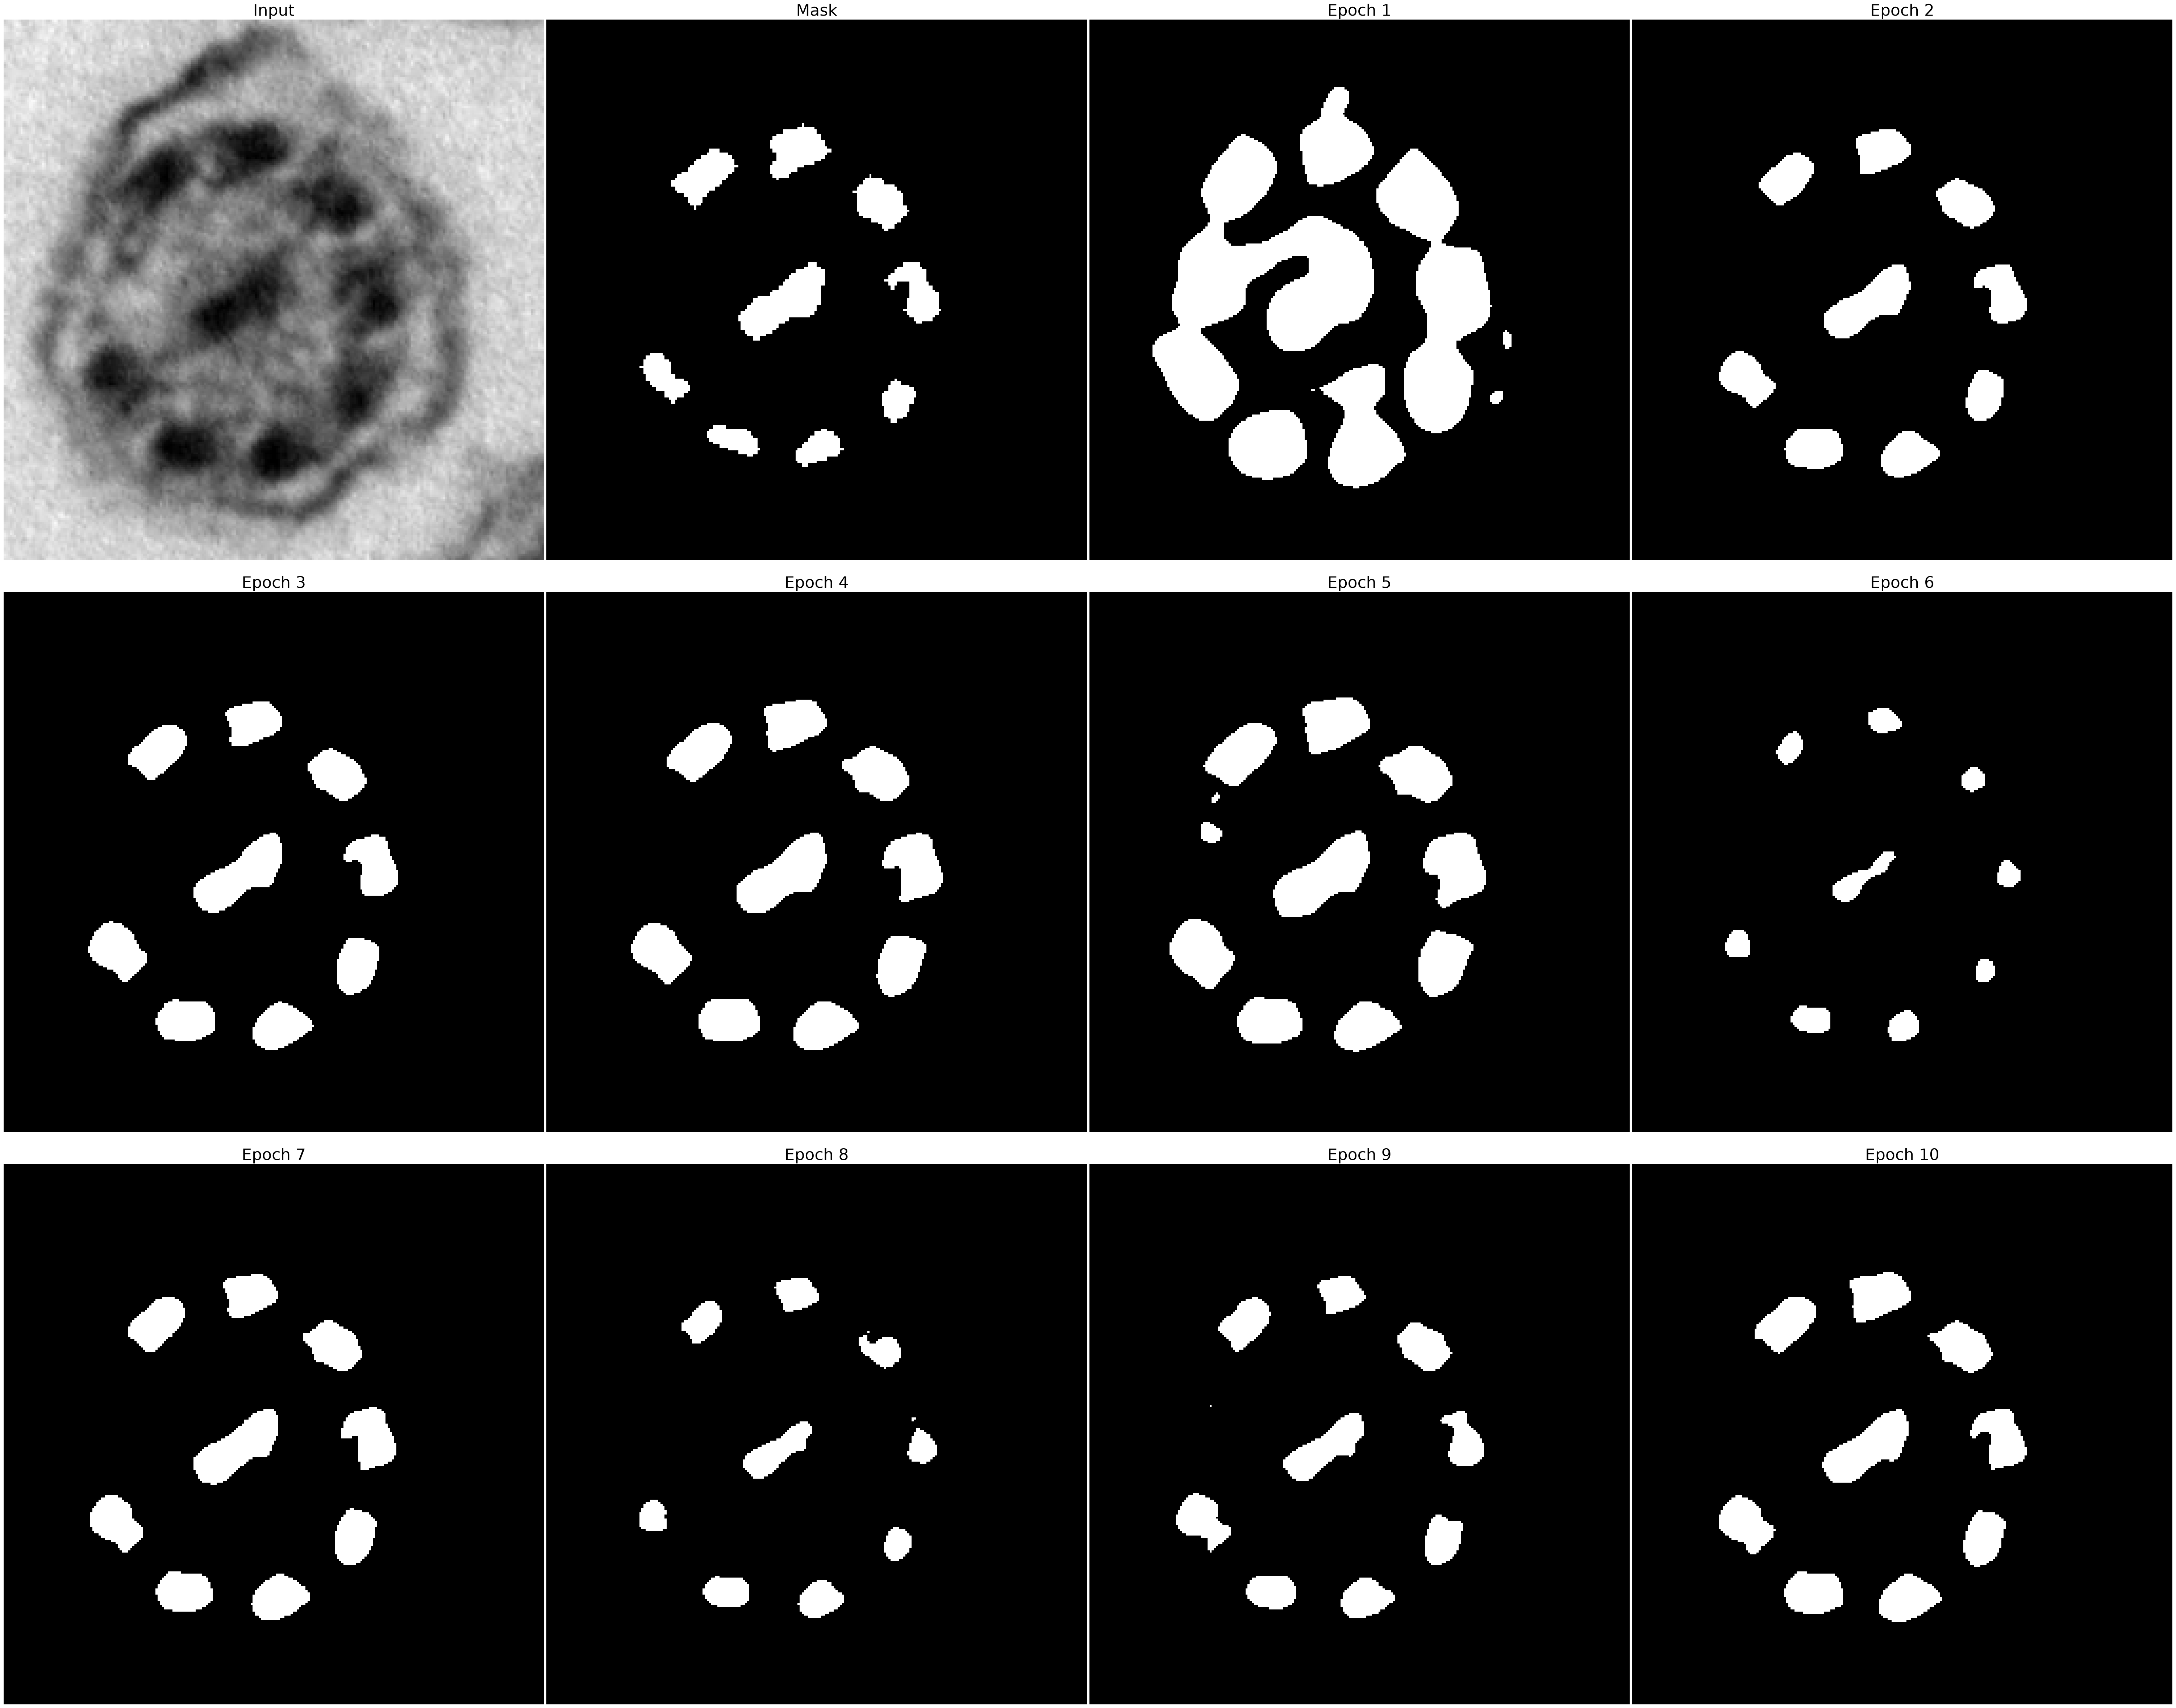

In [5]:
img_show = (preview_img.cpu().numpy().squeeze() * 255).astype(np.uint8)
mask_show = (preview_mask.cpu().numpy().squeeze() * 255).astype(np.uint8)
titles = ["Input", "Mask"]
for i in range(num_epochs):
    titles.append(f"Epoch {i+1}")


plot_images(img_show, mask_show, *epoch_outs, titles=titles)

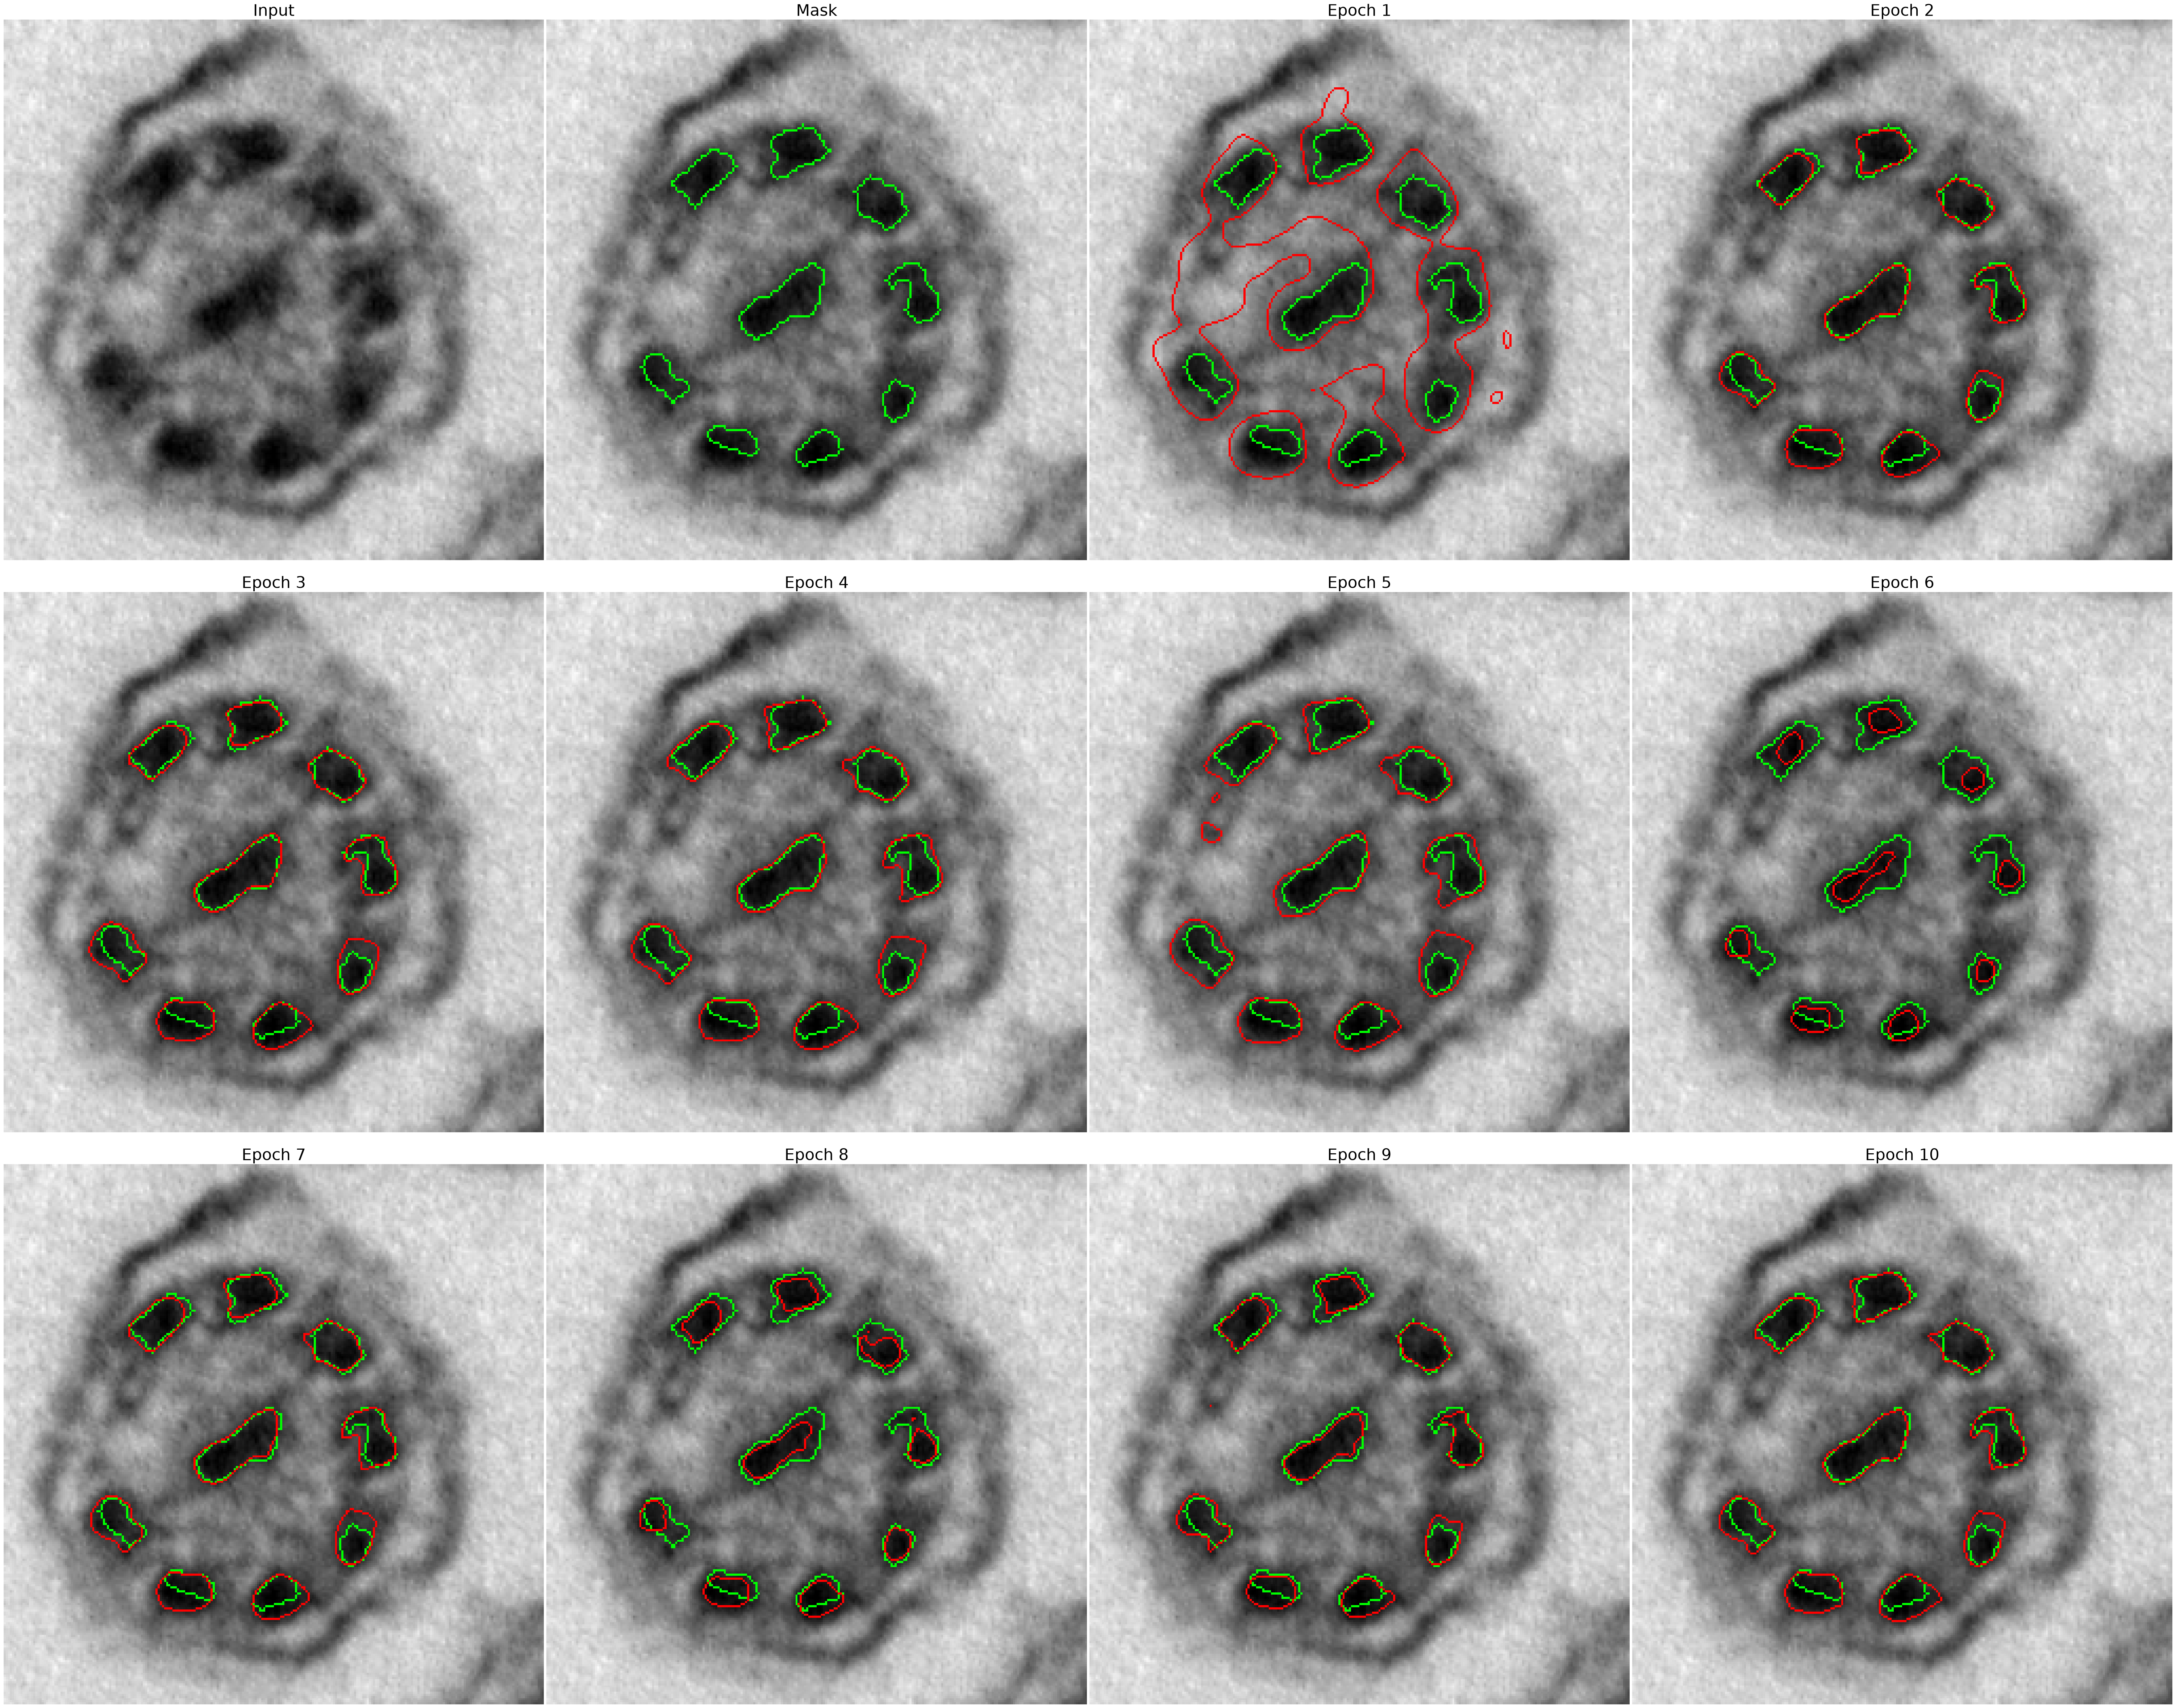

In [7]:
contours_true = find_contours_util(mask_show)
if img_show.ndim == 2:
    img_show = cv2.cvtColor(img_show, cv2.COLOR_GRAY2BGR)

masked_true = draw_contours_util(img_show, contours_true, color=(0, 255, 0), fill=False)

masked_epoch = [draw_contours_util(masked_true, find_contours_util(e), color=(0, 0, 255), fill=False) for e in epoch_outs]
plot_images(img_show, masked_true, *masked_epoch, titles=titles)

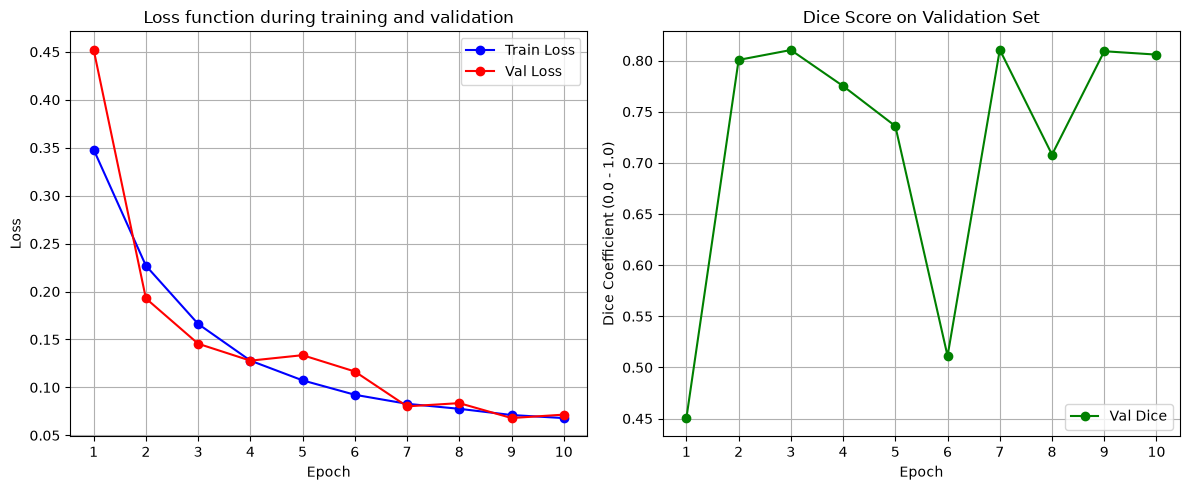

In [11]:
epochs = list(range(1, len(history) + 1)) if len(history) > 0 else list(range(1, num_epochs + 1))
plot_train_loss_dice(history, epochs)

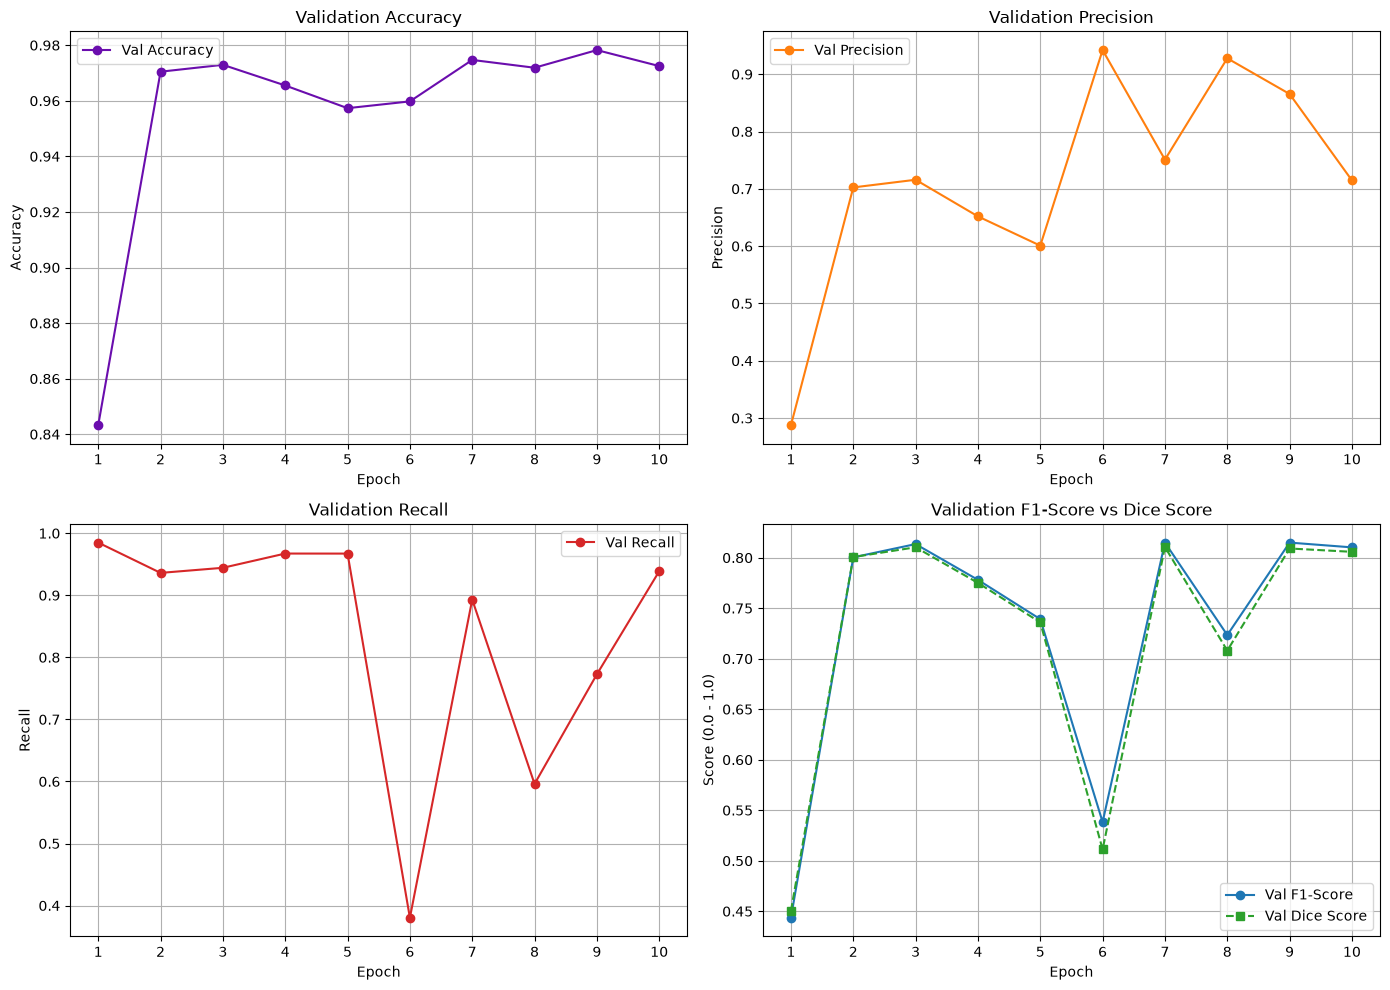

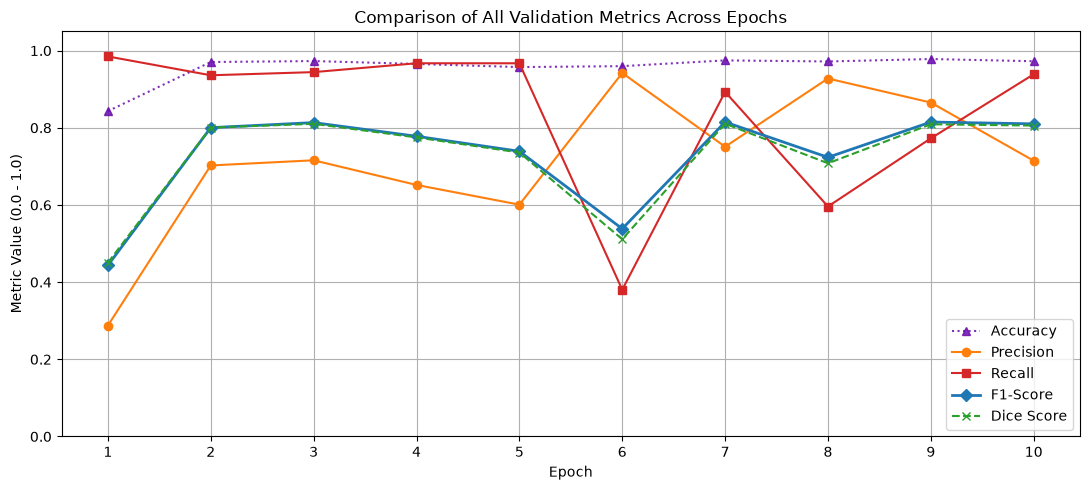

In [ ]:
plot_metrics(history, epochs)

Validation Confusion Matrix and Metrics:
  TP: 273,849
  TN: 4,251,205
  FP: 110,425
  FN: 17,577
  accuracy: 0.9725
  precision: 0.7126
  recall: 0.9397
  f1_score: 0.8106
  dice: 0.8106


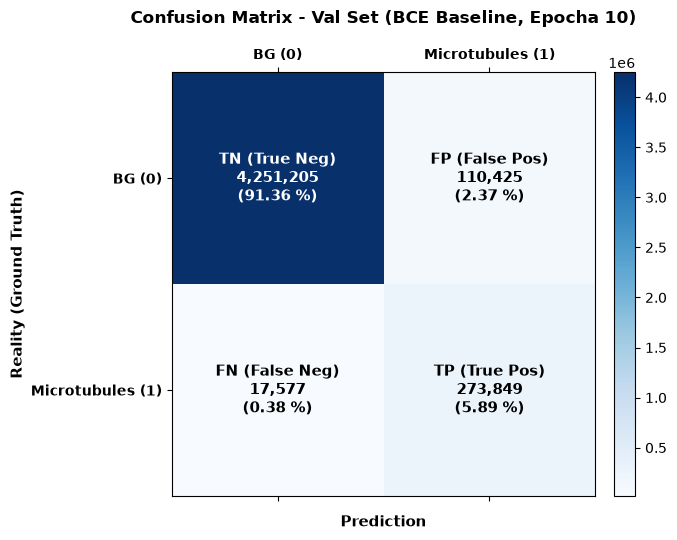

In [14]:
cm_metrics = calculate_dataset_metrics_and_cm(model, val_dataloader, device=device)
print('Validation Confusion Matrix and Metrics:')
for k, v in cm_metrics.items():
    if isinstance(v, int):
        print(f'  {k}: {v:,}')
    else:
        print(f'  {k}: {v:.4f}')

fig = plot_confusion_matrix(cm_metrics, title='Confusion Matrix - Val Set (BCE Baseline, Epocha 10)', save_path='../IMGS2/BCE/confusion_matrix.png')
plt.show()
